# TP3 · Modelos, errores y decisión final · Grupo 9

Esta notebook reúne la evidencia del TP y completa el análisis data-centered.
Reutiliza las predicciones externas existentes: **no entrena ni abre test.csv**.
El baseline es la regresión logística calibrada sin GPU asignada; el final es HistGB.
Los resultados nuevos son descriptivos y posteriores a la búsqueda histórica.

El informe completo está en `reports/analisis_consigna.md`. Para regenerar sus tablas,
ejecutar esta notebook desde el repo con el entorno del proyecto instalado.

In [1]:
from pathlib import Path
import importlib.util
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src/compe").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/compe").is_dir():
    raise RuntimeError("Abrir la notebook desde la raíz del repo o notebooks/.")
sys.path.insert(0, str(ROOT / "src"))
spec = importlib.util.spec_from_file_location("analisis_tp3", ROOT / "experiments/analisis_consigna/analizar.py")
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)
analysis.main()

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

RESULTS = ROOT / "experiments/analisis_consigna"
comparison = pd.read_csv(RESULTS / "comparacion_modelos.csv")
cohorts = pd.read_csv(RESULTS / "cohortes.csv")
delta = pd.read_csv(RESULTS / "mejoras_cohortes.csv")

                modelo       ba  roc_auc  delta_ba_pp   FP   FN
              logistic 0.820110 0.903871     0.000000 4027 2862
     gradient_boosting 0.842726 0.932662     2.261653 3159 2761
hist_gradient_boosting 0.848293 0.935542     2.818336 3253 2516
Cohortes y etiquetas verificadas; sin entrenamiento ni acceso al holdout.


Matplotlib is building the font cache; this may take a moment.


## Datos y preprocesamiento

TRAIN contiene 38.274 filas. Se conserva el split previo al preprocesamiento.
Se excluyen target, estado y fecha de estado; GPU asignada también se excluye del candidato.
Nulos y categorías raras se tratan dentro del entrenamiento de cada fold.
Los modelos lineales usan one-hot, logaritmos y escalado; HistGB usa categorías nativas.
Las decisiones completas y el EDA están en `01_eda.ipynb` y `reports/eda_decisiones.md`.

La CV principal utiliza cinco folds agrupados; el corte de cada fold se elige con tres
folds internos. La búsqueda histórica de hiperparámetros no fue totalmente anidada.
El agrupamiento original usa las entradas originales; el control posterior con las
entradas efectivas obtuvo 84,68% BA para HistGB (`output/revision_modelos_20261116/`).

## Baseline y dos métricas

**Baseline:** regresión logística, C=0,01677985, class_weight=balanced y l1_ratio=0.
Es la referencia lineal del informe; no es el ensemble enviado en la primera entrega.

**Balanced accuracy** pondera ambos recalls por igual y es la métrica principal de
competencia. **ROC-AUC** permite analizar el ordenamiento de scores sin fijar un corte.
La selección histórica usó BA, gap y simplicidad; AUC se registró como diagnóstico.
Esta comparación informa ambas sin redefinir retrospectivamente el objetivo de búsqueda.

,modelo,ba,ba_std_folds,roc_auc,delta_ba_pp,FP,FN
0,logistic,0.820110,0.013856,0.903871,0.000000,4027,2862
1,gradient_boosting,0.842726,0.015028,0.932662,2.261653,3159,2761
2,hist_gradient_boosting,0.848293,0.010295,0.935542,2.818336,3253,2516


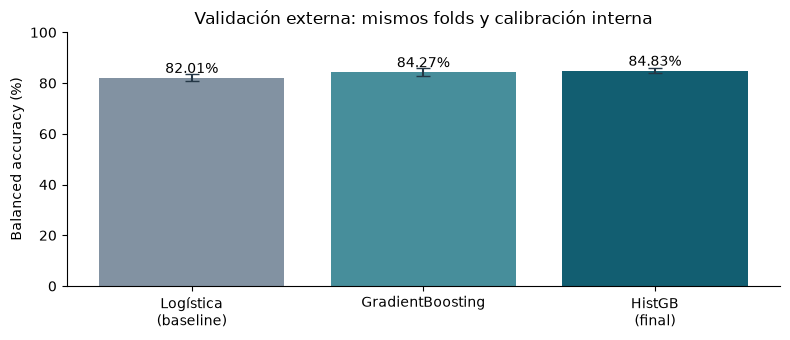

In [2]:
display(comparison[["modelo", "ba", "ba_std_folds", "roc_auc", "delta_ba_pp", "FP", "FN"]])
fig, ax = plt.subplots(figsize=(8, 3.5))
labels = ["Logística\n(baseline)", "GradientBoosting", "HistGB\n(final)"]
ax.bar(labels, 100 * comparison.ba, color=["#8292A2", "#478E9B", "#125E71"])
ax.errorbar(labels, 100 * comparison.ba, yerr=100 * comparison.ba_std_folds,
            fmt="none", color="#243746", capsize=5)
ax.set_ylim(0, 100)
ax.set_ylabel("Balanced accuracy (%)")
ax.set_title("Validación externa: mismos folds y calibración interna")
ax.spines[["top", "right"]].set_visible(False)
for i, v in enumerate(comparison.ba):
    ax.text(i, 100 * v + 2, f"{v:.2%}", ha="center")
fig.tight_layout()
plt.show()

## Errores del baseline y del final por cohortes

Se incluyen todas las categorías de client_type, service_tier y reserved_gpu_type.
FP: completado marcado como cancelación. FN: cancelado marcado como vigente.
Cada dimensión reconstruye la matriz global; dimensiones diferentes se superponen.
BA/AUC no se definen sin ambas clases. `soporte_bajo` indica menos de 30 casos de alguna
clase; las métricas de categorías diminutas no justifican conclusiones de generalización.

In [3]:
for dimension in analysis.COHORTS:
    display(Markdown(f"### {dimension}"))
    display(cohorts[(cohorts.dimension == dimension) & cohorts.modelo.isin(
        ["logistic", "hist_gradient_boosting"])][[
        "modelo", "cohorte", "n", "n0", "n1", "ba", "roc_auc", "recall",
        "especificidad", "FP", "FN", "pct_FN_total", "soporte_bajo"]])
    display(delta[delta.dimension == dimension])

### client_type

,modelo,cohorte,n,n0,n1,ba,roc_auc,recall,especificidad,FP,FN,pct_FN_total,soporte_bajo
0,logistic,cloud_marketplace,18717,11618,7099,0.742474,0.808394,0.767009,0.717938,3277,1654,0.577918,False
1,logistic,enterprise_client,1350,1093,257,0.740225,0.868051,0.509728,0.970723,32,126,0.044025,False
2,logistic,high_priority_partner,116,91,25,0.552527,0.789011,0.160000,0.945055,5,21,0.007338,True
3,logistic,independent_client,2896,2419,477,0.615628,0.759981,0.276730,0.954527,110,345,0.120545,False
4,logistic,managed_account,8306,4733,3573,0.903576,0.958812,0.873496,0.933657,314,452,0.157932,False
5,logistic,research_consortium,6655,2150,4505,0.909066,0.981502,0.946504,0.871628,276,241,0.084207,False
6,logistic,sponsored_project,233,206,27,0.561039,0.575692,0.185185,0.936893,13,22,0.007687,True
7,logistic,unknown,1,0,1,NaN,NaN,0.000000,NaN,0,1,0.000349,True
44,hist_gradient_boosting,cloud_marketplace,18717,11618,7099,0.774939,0.861656,0.773067,0.776812,2593,1611,0.640302,False
45,hist_gradient_boosting,enterprise_client,1350,1093,257,0.784741,0.898600,0.591440,0.978042,24,105,0.041733,False


,dimension,cohorte,n,n0,n1,soporte_bajo,ba_baseline,ba_final,delta_ba,roc_auc_baseline,roc_auc_final,delta_roc_auc,FP_baseline,FP_final,delta_FP,FN_baseline,FN_final,delta_FN
0,client_type,cloud_marketplace,18717,11618,7099,False,0.742474,0.774939,0.032466,0.808394,0.861656,0.053262,3277,2593,-684,1654,1611,-43
1,client_type,enterprise_client,1350,1093,257,False,0.740225,0.784741,0.044516,0.868051,0.898600,0.030548,32,24,-8,126,105,-21
2,client_type,high_priority_partner,116,91,25,True,0.552527,0.679560,0.127033,0.789011,0.775824,-0.013187,5,11,6,21,13,-8
3,client_type,independent_client,2896,2419,477,False,0.615628,0.646381,0.030753,0.759981,0.802901,0.042921,110,88,-22,345,320,-25
4,client_type,managed_account,8306,4733,3573,False,0.903576,0.930438,0.026861,0.958812,0.985336,0.026525,314,273,-41,452,291,-161
5,client_type,research_consortium,6655,2150,4505,False,0.909066,0.923584,0.014518,0.981502,0.990808,0.009307,276,257,-19,241,150,-91
6,client_type,sponsored_project,233,206,27,True,0.561039,0.520047,-0.040992,0.575692,0.534340,-0.041352,13,7,-6,22,25,3
7,client_type,unknown,1,0,1,True,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,1,1,0


### service_tier

,modelo,cohorte,n,n0,n1,ba,roc_auc,recall,especificidad,FP,FN,pct_FN_total,soporte_bajo
8,logistic,basic,5081,3133,1948,0.740787,0.804563,0.776181,0.705394,923,436,0.152341,False
9,logistic,enterprise,9,4,5,1.000000,1.000000,1.000000,1.000000,0,0,0.000000,True
10,logistic,priority,3211,2029,1182,0.840788,0.913812,0.812183,0.869394,265,222,0.077568,False
11,logistic,standard,29973,17144,12829,0.831302,0.915223,0.828202,0.834403,2839,2204,0.770091,False
52,hist_gradient_boosting,basic,5081,3133,1948,0.766440,0.856831,0.772587,0.760294,751,443,0.176073,False
53,hist_gradient_boosting,enterprise,9,4,5,1.000000,1.000000,1.000000,1.000000,0,0,0.000000,True
54,hist_gradient_boosting,priority,3211,2029,1182,0.885497,0.956595,0.864636,0.906358,190,160,0.063593,False
55,hist_gradient_boosting,standard,29973,17144,12829,0.858014,0.943046,0.850885,0.865142,2312,1913,0.760334,False


,dimension,cohorte,n,n0,n1,soporte_bajo,ba_baseline,ba_final,delta_ba,roc_auc_baseline,roc_auc_final,delta_roc_auc,FP_baseline,FP_final,delta_FP,FN_baseline,FN_final,delta_FN
8,service_tier,basic,5081,3133,1948,False,0.740787,0.766440,0.025653,0.804563,0.856831,0.052268,923,751,-172,436,443,7
9,service_tier,enterprise,9,4,5,True,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0,0,0,0,0,0
10,service_tier,priority,3211,2029,1182,False,0.840788,0.885497,0.044709,0.913812,0.956595,0.042783,265,190,-75,222,160,-62
11,service_tier,standard,29973,17144,12829,False,0.831302,0.858014,0.026711,0.915223,0.943046,0.027823,2839,2312,-527,2204,1913,-291


### reserved_gpu_type

,modelo,cohorte,n,n0,n1,ba,roc_auc,recall,especificidad,FP,FN,pct_FN_total,soporte_bajo
12,logistic,GPU_T1,30118,17031,13087,0.836333,0.920175,0.836250,0.836416,2786,2143,0.748777,False
13,logistic,GPU_T12,6,0,6,NaN,NaN,0.000000,NaN,0,6,0.002096,True
14,logistic,GPU_T2,529,339,190,0.728334,0.787968,0.663158,0.793510,70,64,0.022362,False
15,logistic,GPU_T3,7,3,4,1.000000,1.000000,1.000000,1.000000,0,0,0.000000,True
16,logistic,GPU_T4,5777,3754,2023,0.754381,0.820636,0.750371,0.758391,907,505,0.176450,False
17,logistic,GPU_T5,740,498,242,0.756572,0.823584,0.681818,0.831325,84,77,0.026904,False
18,logistic,GPU_T6,883,524,359,0.761108,0.821366,0.852368,0.669847,173,53,0.018519,False
19,logistic,GPU_T7,214,161,53,0.846185,0.899449,0.735849,0.956522,7,14,0.004892,False
56,hist_gradient_boosting,GPU_T1,30118,17031,13087,0.863249,0.948296,0.859020,0.867477,2257,1845,0.733307,False
57,hist_gradient_boosting,GPU_T12,6,0,6,NaN,NaN,0.000000,NaN,0,6,0.002385,True


,dimension,cohorte,n,n0,n1,soporte_bajo,ba_baseline,ba_final,delta_ba,roc_auc_baseline,roc_auc_final,delta_roc_auc,FP_baseline,FP_final,delta_FP,FN_baseline,FN_final,delta_FN
12,reserved_gpu_type,GPU_T1,30118,17031,13087,False,0.836333,0.863249,0.026916,0.920175,0.948296,0.028121,2786,2257,-529,2143,1845,-298
13,reserved_gpu_type,GPU_T12,6,0,6,True,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,6,6,0
14,reserved_gpu_type,GPU_T2,529,339,190,False,0.728334,0.771511,0.043177,0.787968,0.851902,0.063934,70,55,-15,64,56,-8
15,reserved_gpu_type,GPU_T3,7,3,4,True,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0,0,0,0,0,0
16,reserved_gpu_type,GPU_T4,5777,3754,2023,False,0.754381,0.789591,0.035210,0.820636,0.872874,0.052238,907,728,-179,505,459,-46
17,reserved_gpu_type,GPU_T5,740,498,242,False,0.756572,0.769740,0.013168,0.823584,0.851754,0.028171,84,75,-9,77,75,-2
18,reserved_gpu_type,GPU_T6,883,524,359,False,0.761108,0.784909,0.023802,0.821366,0.862351,0.040985,173,132,-41,53,64,11
19,reserved_gpu_type,GPU_T7,214,161,53,False,0.846185,0.877593,0.031407,0.899449,0.935896,0.036447,7,6,-1,14,11,-3


Entre las categorías con soporte suficiente, el baseline tiene menor BA en
independent_client (61,56%), basic (74,08%) y GPU_T2 (72,83%).
El volumen de errores también importa: cloud_marketplace concentra 57,79% de sus FN.
HistGB mejora la BA en esas cohortes, pero las mejoras no son universales:
basic pasa de 436 a 443 FN y GPU_T6 de 53 a 64, pese a mejorar su BA.

## Cohorte prioritaria: reservas creadas con 0–7 horas de anticipación

El campo hours_before_execution mide creación→ejecución, **en horas** según la consigna.
No mide tiempo restante desde la predicción semanal ni cuándo ocurrió la cancelación.
Esta cohorte tiene 5.220 reservas (13,64% de TRAIN). HistGB detecta solo 25,29% de sus
cancelaciones, con 517 FN, el 20,55% de todos sus FN. El problema persiste frente al baseline.

In [4]:
display(cohorts[(cohorts.dimension == "anticipacion") & (cohorts.cohorte == "0-7")][[
    "modelo", "n", "pct_filas", "ba", "recall", "FP", "FN", "pct_FN_total"]])

,modelo,n,pct_filas,ba,recall,FP,FN,pct_FN_total
20,logistic,5220,0.136385,0.608921,0.296243,355,487,0.170161
42,gradient_boosting,5220,0.136385,0.604485,0.223988,68,537,0.194495
64,hist_gradient_boosting,5220,0.136385,0.614188,0.252890,111,517,0.205485


**Impacto operativo posible:** las cancelaciones omitidas pueden retener capacidad
que no se usa; con poca anticipación hay menos margen para ofrecerla nuevamente.
Los FP podrían provocar contactos o reasignaciones incorrectas. No se monetiza el impacto
porque no se conocen costos ni política de actuación.

**Hipótesis:** faltan señales actuales de confirmación, preparación del workload y actividad.
El análisis observacional no prueba causas ni que una nueva variable vaya a mejorar.

**Intervención propuesta:** capturar eventos con fecha, confirmación, contenedor/datos
preparados y pago acreditado. Obtener IDs estables y fotografías semanales de reservas
activas; construir features usando exclusivamente información anterior a cada predicción.
Comparar con/sin nuevas señales sobre datos futuros reservados y medir BA/AUC globales,
recall/FPR de la cohorte y FN por 1.000 reservas. Validar también por cliente y tiempo.
No se afirma que la intervención haya sido ejecutada.

## Curva de aprendizaje y adquisición de datos

Las curvas varían cantidad de entrenamiento, mantienen completa la validación y eligen
cortes internamente. La logística converge cerca del 82% con brecha pequeña: limitación
de capacidad. HistGB mejora con más datos, con rendimientos decrecientes; su brecha baja.
La ganancia observada no garantiza una extrapolación a poblaciones distintas.

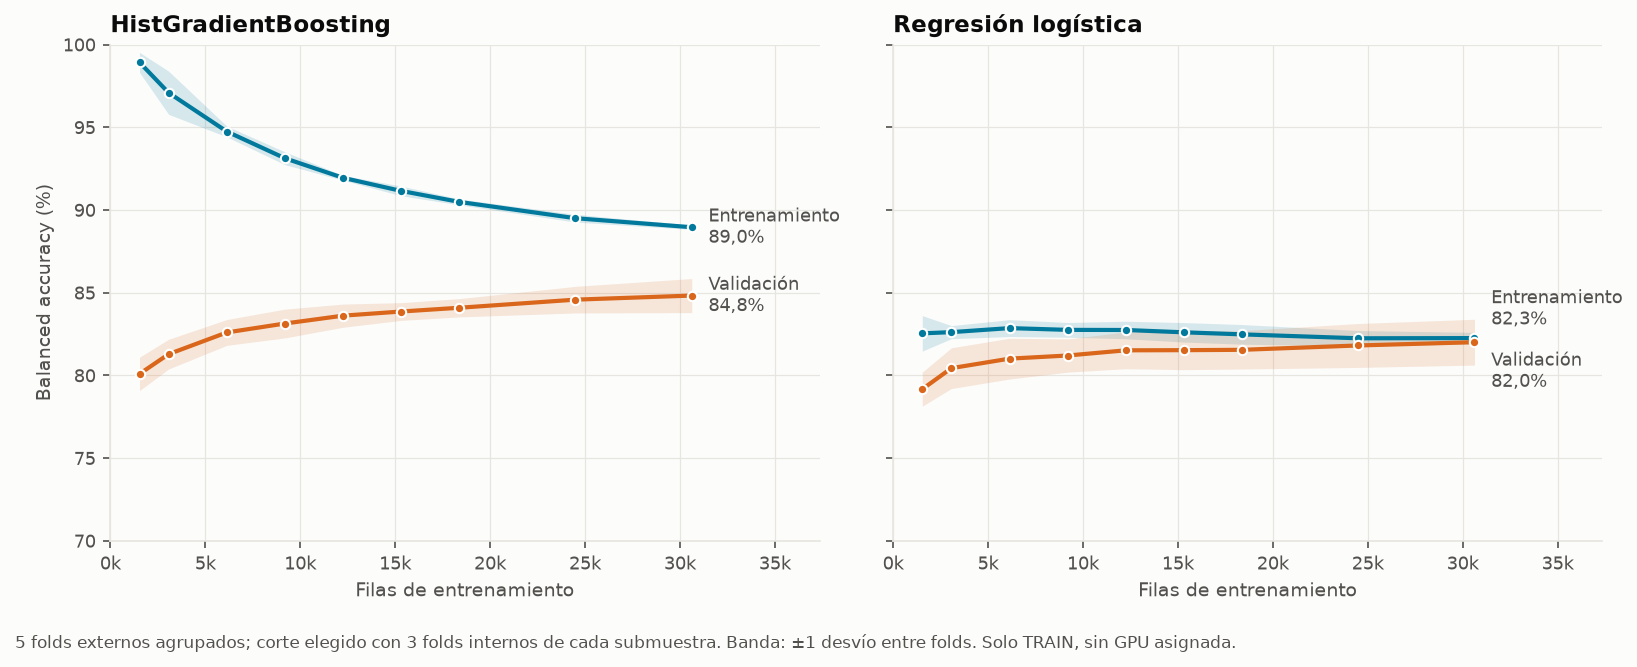

# Adquisición de datos (consigna 3.4)

Qué datos incorporaríamos y por qué esperamos que mejoren el sistema. La propuesta se apoya en dos evidencias:
- la [curva de aprendizaje](curva_aprendizaje.md) (3.2);
- dónde se concentran los errores fuera de fold del HistGB elegido ([evidencia.py](../experiments/adquisicion_datos/evidencia.py), [evidencia_errores.csv](../experiments/adquisicion_datos/evidencia_errores.csv)).

Todo sale de TRAIN, con el corte interno de cada fold y sin GPU asignada; `test.csv` no se usó. Los segmentos son descriptivos y se superponen: muestran dónde falta información, no prueban qué dato la resolvería.

## Punto de partida

- **Más filas del mismo tipo rinden poco.** HistGB gana alrededor de +1 punto de BA cada vez que se duplican las filas. Reentrenar con train+test daría del orden de +0,5 puntos, por extrapolación. La logística ya está estancada. El límite principal es la **información** de las variables, no la cantidad de filas.
- **Muchos errores no son dudosos.** El 28% de los errores (1.612 de 5.769) tiene un score a más de 0,25 del corte: el modelo se equivoca con confianza. Eso apunta a información que falta, no a ruido cerca del corte.

## Dónde falla el modelo (OOF de TRAIN, BA global 84,83%)

| Segmento | Filas | BA | Recall | Parte de los falsos negativos | Parte del error total |
|---|---:|---:|---:|---:|---:|
| Sin historial previo del cliente | 91,2% | 83,3% | 81,6% | 98,2% | 99,0% |
| Con historial previo | 8,8% | **98,4%** | 98,2% | 1,8% | 1,0% |
| Anticipación de 0 a 7 horas | 13,6% | **61,4%** | **25,3%** | 20,6% | 10,9% |
| Anticipación de 8 a 30 horas | 15,7% | 78,1% | 70,2% | 21,3% | 19,5% |
| Con pedidos especiales | 39,9% | **70,5%** | **51,8%** | 63,8% | 50,3% |
| Regiones distintas de PRT | 61,4% | 80,9% | 74,9% | 63,3% | 66,8% |
| `no_show` (cancelados de hecho) | 1,1% | — | **44,6%** | 9,4% | 4,1% |
| Sin `locked_allocation` | 83,9% | 79,9% | 74,4% | 100% | 99,9% |

«Sin historial previo» significa `returning_client = 0`, sin cancelaciones previas y sin trabajos previos exitosos. La fila de regiones suma las frecuentes y las raras.

La anticipación usa `hours_before_execution`: horas entre creación y ejecución programada según el enunciado. No mide el tiempo restante desde una predicción semanal ni la fecha real de cancelación. El análisis de las tres cohortes exigidas, el baseline y la intervención prioritaria se completa en [análisis de errores](analisis_consigna.md).

## Datos que incorporaríamos, por prioridad

### 1. Historial del cliente con un identificador estable
**Qué:** un ID de cliente que permita unir sus reservas. Con él se calculan cancelaciones y finalizaciones previas reales, la tasa histórica de cancelación, el tiempo desde la última reserva y las reservas activas al mismo tiempo.

**Por qué:** es el mayor salto observado. Cuando hay historial la BA es 98,4%; el 91% de las reservas no lo tiene y concentra el 99% de los errores. Probablemente muchos de esos clientes no son nuevos: simplemente sus reservas no están vinculadas, como ocurre con los huéspedes en el dataset de hoteles del que parece venir este. También ayuda frente al cambio de distribución, porque describe al cliente y no a su región.

**Cuidado:** el historial tiene que calcularse solo con reservas anteriores a la que se predice, y como estaba al momento de predecir. Si no, hay fuga.

### 2. Eventos de la reserva con fecha
**Qué:** la fecha de creación y la de cada modificación, qué cambió (fecha, recursos, cantidad de horas) y los días desde el último cambio. Hoy solo existe el conteo `resource_modifications`.

**Por qué:** el modelo detecta pocas cancelaciones entre las reservas creadas con poca anticipación. Con anticipación de 0 a 7 horas detecta el 25% de las cancelaciones (BA 61,4%), y entre 0 y 30 horas se acumula el 42% de los falsos negativos. Los eventos recientes podrían aportar información: es una hipótesis que requiere medir su disponibilidad y utilidad, no una causa demostrada por estos datos.

### 3. Señales de preparación cerca de la ejecución
**Qué:** si se confirmó la reserva, si se cargaron los datos o la imagen del contenedor, si el pago o el depósito se acreditó de verdad, y la actividad del cliente en la plataforma en las 24 a 72 horas previas.

**Por qué:** los `no_show` se parecen a los completados en todas las variables actuales. Se detecta el 44,6% y explican el 9,4% de los falsos negativos. Su diferencia está en el comportamiento cerca de la ejecución, y eso es lo que miden estas señales. También explicaría parte de los errores con confianza.

**Cuidado:** hay que definir el momento en que se predice, por ejemplo 72 horas antes, y usar solo lo que se conoce en ese momento. Es la misma lección de `assigned_gpu_type`.

### 4. Detalle de los pedidos especiales
**Qué:** el tipo de cada pedido, no solo la cantidad, y si fue atendido o rechazado.

**Por qué:** con pedidos el recall cae al 51,8% (BA 70,5%) y ahí está el 64% de los falsos negativos. Hoy el pedido funciona como señal de compromiso, pero el modelo no distingue a quien pidió algo y después canceló. Un pedido rechazado puede explicar justamente esa cancelación.

### 5. Más reservas de regiones fuera de PRT, y su fecha de registro
**Qué:** más filas de clientes de otras regiones y la fecha en que se registró cada reserva, para poder validar en orden temporal.

**Por qué:** esas regiones son el 61% de las filas y explican el 67% del error. Entrenar solo con PRT y evaluar en el resto da alrededor de 51%: es la principal debilidad ante un test distinto. La curva de aprendizaje indica que sumar filas sin elegirlas rinde poco. Si se suman, conviene que sean de esta cohorte.

### Prioridad baja
- **Hora de la reasignación de GPU.** Permitiría usar `assigned_gpu_type` sin fuga cuando la reasignación ocurre antes del momento de predecir. Hoy aporta solo unos 0,3 puntos.
- **Política de cancelación detallada** (penalidad, plazos) y cambios de precio desde que se reservó. Hoy el costo tiene poca señal propia y `locked_allocation` ya se predice casi perfecto.
- **Más filas al azar del mismo tipo.** Según 3.2, rinden alrededor de +1 punto por cada duplicación.

## Cómo validaríamos cada fuente nueva

Se usa el mismo protocolo: folds agrupados, corte elegido con folds internos, y resultados por subgrupos y con validación dejando afuera un año o una región. Una fuente entra solo si:
1. mejora la BA más que el desvío entre folds;
2. no empeora a las cohortes débiles (sin historial, anticipación corta, fuera de PRT);
3. está disponible en el momento de predecir.

## Para la diapositiva

**Adquisición de datos: más información, no más filas**
- La curva de aprendizaje muestra unos +1 punto por cada duplicación de filas. El límite es la información de las variables.
- **1. Historial del cliente** con un ID estable: con historial la BA es 98%, y sin historial están el 91% de las reservas y el 99% de los errores.
- **2. Eventos con fecha y señales cercanas a la ejecución:** con 0 a 7 horas de anticipación entre creación y ejecución se detecta el 25% de las cancelaciones, y los `no_show` se detectan en un 45%.
- **3. Detalle de pedidos especiales y más datos fuera de PRT:** las cohortes con más error (BA de 70,5% y de 80,9%).
- Toda variable nueva tiene que existir al momento de predecir y se acepta solo si mejora la CV más que la variación entre folds.


In [5]:
display(Image(filename=str(ROOT / "experiments/curva_aprendizaje/curva_aprendizaje.png")))
display(Markdown((ROOT / "reports/adquisicion_datos.md").read_text()))

## Estrategias exploradas y decisión final

- Comparar familias: HistGB mejora al baseline +2,82 pp BA y +0,03167 AUC.
- Ajustar hiperparámetros: búsquedas amplias, refinamientos y confirmaciones registradas;
  más complejidad no justificó reemplazar el HistGB final de 100 iteraciones y 31 hojas.
- Ensembles: promedio y stacking no mejoran BA con el mismo protocolo externo.
  Stacking mejora ligeramente AUC, pero no BA: se mantiene HistGB por el objetivo y simplicidad.

In [6]:
ensembles = pd.read_csv(ROOT / "experiments/seleccion/stacking_resultados/a92fbb4e4778849e/resultados/metricas_externas_globales.csv")
display(ensembles[ensembles.escenario == "cv"][["modelo", "balanced_accuracy", "roc_auc", "FP", "FN"]])

,modelo,balanced_accuracy,roc_auc,FP,FN
0,histgb,0.848293,0.935542,3253,2516
1,promedio,0.847296,0.935248,3345,2482
2,stacking,0.846576,0.935816,3127,2661


**Final:** HistGB sin assigned; umbral fijo 0,38294747099493937. BA externa 84,83%.
El holdout interno ya evaluado dio BA 85,09%, AUC 0,93774; no se lo vuelve a consultar aquí.
Las pruebas por años excluidos dieron 77,47–84,32% BA y la extrapolación regional extrema
llegó a 51,47%. El rendimiento del test oculto depende de su distribución.

## Entrega y contrato

`predictor_v1_Grupo_9(X)`, `predictor_v2_Grupo_9(X)` y `predictor(X)` devuelven el mismo
ndarray 0/1, una etiqueta por fila y mismo orden. No ajustan el modelo ni su umbral.
El nombre v1 satisface el nombre pedido por el PDF sin cambiar las predicciones v2.

El artefacto se probó en un entorno local limpio de Python 3.12 con versiones exactas,
sin warnings y con predicciones idénticas al ejemplo. Esa prueba no equivale a Colab.
`entrega/validacion_colab.ipynb` permite verificarlo allí.
Sigue pendiente confirmar que el evaluador entregue high_value_client y ambos totales.
No se rellenan ni aproximan esas entradas porque son features activas del modelo.

In [7]:
import json
display(json.loads((ROOT / "entrega/compatibilidad_py312.json").read_text()))

{'python': '3.12.12',
 'platform': 'macOS-15.7.3-arm64-arm-64bit',
 'runtime': 'local',
 'dependencies': {'numpy': '2.5.4',
  'pandas': '3.1.1',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'joblib': '1.6.0',
  'threadpoolctl': '3.8.0'},
 'expected_dependencies': {'numpy': '2.5.4',
  'pandas': '3.1.1',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'joblib': '1.6.0',
  'threadpoolctl': '3.8.0'},
 'predictor_sha256': 'c8f9f8e8ad7c9ef554e45b3f58eebe4fa958e2a40d6bfe7a0353019b03147c2f',
 'test_csv_accessed': False,
 'retrained': False,
 'status': 'OK',
 'rows_compared': 300,
 'labels_match': True,
 'max_score_error': 0.0,
 'v1_v2_equivalent': True,
 'order_preserved': True,
 'input_unchanged': True,
 'optional_columns_supported': True,
 'missing_active_features_rejected': True,
 'warnings': []}